# Pair B, Phase II (AI-aided). Model A vs Model B: same accuracy, different reasons

*AI-aided: scripts and notebook drafted with Claude Code, every number checked against the computed outputs; see `ai-interactions/phase2_ai_log.md`.*

Phase I found that the two models are almost equally accurate (63.0 % vs 63.0 %) but pick different neighbours and break under different edits. `pairB_phase2_modelB.ipynb` opened Model B. This notebook applies the **same techniques to Model A** and puts both side by side.

Model A: 5 numbers z-scored (age, hospital stay, labs, medications, diagnoses) + 10 categorical fields one-hot → 127-D vector → 10 nearest other patients (cosine) → majority vote. It reads exactly the same 15 fields as Model B; Model B reads them as a sentence.

| Question | Technique | Model A | Model B | Section |
|---|---|---|---|---|
| Is it the Phase I model? | Reproduction | step 14 | step 1 | 1 |
| What does the space look like? | Geometry, exact decomposition, variance share | step 14 | steps 2, 5b | 2 |
| Which fields make two stays (dis)similar? | **Shapley values**, same 300 pairs | step 15 | step 3 | 3 |
| What does the outcome actually depend on? | Trained classifiers + **permutation importance** | step 17 | step 17 | 3–4 |
| How does the vote react to one field? | **ICE / PDP**, same 300 stays | step 16 | step 10 | 4 |
| What do the two spaces look like? | UMAP, same 6,000 stays | step 18 | step 6 | 5 |
| Which stays does each model get right, and which are fragile? | Group comparison | step 18 | step 18 | 6 |

Run `scripts/14`–`18` (and `05c`) first; outputs are gitignored. Model A runs in seconds; no GPU needed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import sys
sys.path.insert(0, "scripts")
from common import FIELDS, MODEL_COLORS, NAVY, apply_style
apply_style()
plt.rcParams["figure.dpi"] = 110
OUT, FIG = Path("outputs"), Path("figures")
CA, CB = MODEL_COLORS["model_a"], MODEL_COLORS["model_b"]
geo = json.load(open(OUT / "geometry_A.json"))
{k: round(v, 4) for k, v in geo.items()}

{'reproduction_mean_shared_neighbours': 10.0,
 'reproduction_identical_sets': 1.0,
 'median_d10': 0.1132,
 'median_d10_phase1': 0.1132,
 'differing_sets_explained_by_ties': 1.0,
 'random_pair_cosine': 0.3463,
 'random_pair_cosine_centered': 0.0001,
 'share_identical_record_neighbour1': 0.0009,
 'share_d10_zero': 0.0,
 'median_ratio_sex_swap': 0.6123,
 'mean_flips_sex_swap': 8.8643,
 'spearman_ratio_flips_sex_swap': 0.5835,
 'median_ratio_age_shift': 0.3893,
 'mean_flips_age_shift': 5.4178,
 'spearman_ratio_flips_age_shift': 0.5027,
 'median_ratio_hba1c_elevation': 0.6436,
 'mean_flips_hba1c_elevation': 4.3628,
 'spearman_ratio_flips_hba1c_elevation': 0.2251}

## 1. Reproducing Model A

`14_model_a_geometry.py` rebuilds Model A from the records (the same encoding as `shared/01_prepare_baseline_data.py`) and retrieves the neighbours again: **10.0 of 10** shared on average, **100 %** identical sets, median distance to the 10th neighbour 0.1132 vs. 0.1132 in Phase I. Unlike Model B, Model A can be fed any edited record directly, so all its experiments are exact.

## 2. Two very different spaces

Model A's cosine splits **exactly** into one term per field: cos(q, r) = Σ_f term_f / (|q|·|r|), where term_f = z_q·z_r for a number and 1 or 0 (same value or not) for a category. Every categorical field adds exactly one unit to the squared length, as much as a z-scored number on average, so **by construction every field gets about the same say**.

In [2]:
dec = pd.read_csv(OUT / "model_a_decomposition.csv").set_index("field")
dec.sort_values("lift", ascending=False).round(4)

,neighbour_term,random_term,lift,share_of_similarity
field,,,,
Diagnoses count,0.0554,-0.0001,0.0555,0.0612
Labs,0.0528,-0.0007,0.0535,0.0583
Age,0.0514,0.0002,0.0513,0.0568
Hospital Stay,0.0499,0.0003,0.0496,0.0551
Medications,0.0461,-0.0004,0.0465,0.0509
Insulin,0.0651,0.0214,0.0437,0.0719
Payer,0.0581,0.0183,0.0398,0.0642
Admission Type,0.0656,0.0265,0.0391,0.0725
Specialty,0.0562,0.0210,0.0351,0.0621


**Table 1.** Mean per-field term of the similarity to the 10 neighbours, against random pairs. Every field contributes 0.046–0.069 of the neighbours' similarity (5–8 % each). The largest **lift** over random pairs comes from the five numbers (diagnoses count, labs, age, hospital stay, medications: +0.047 to +0.056), because random stays have z-products near 0. The smallest comes from Max Glucose and A1C (+0.008, +0.014), because most stays share their most common value ("None") anyway.

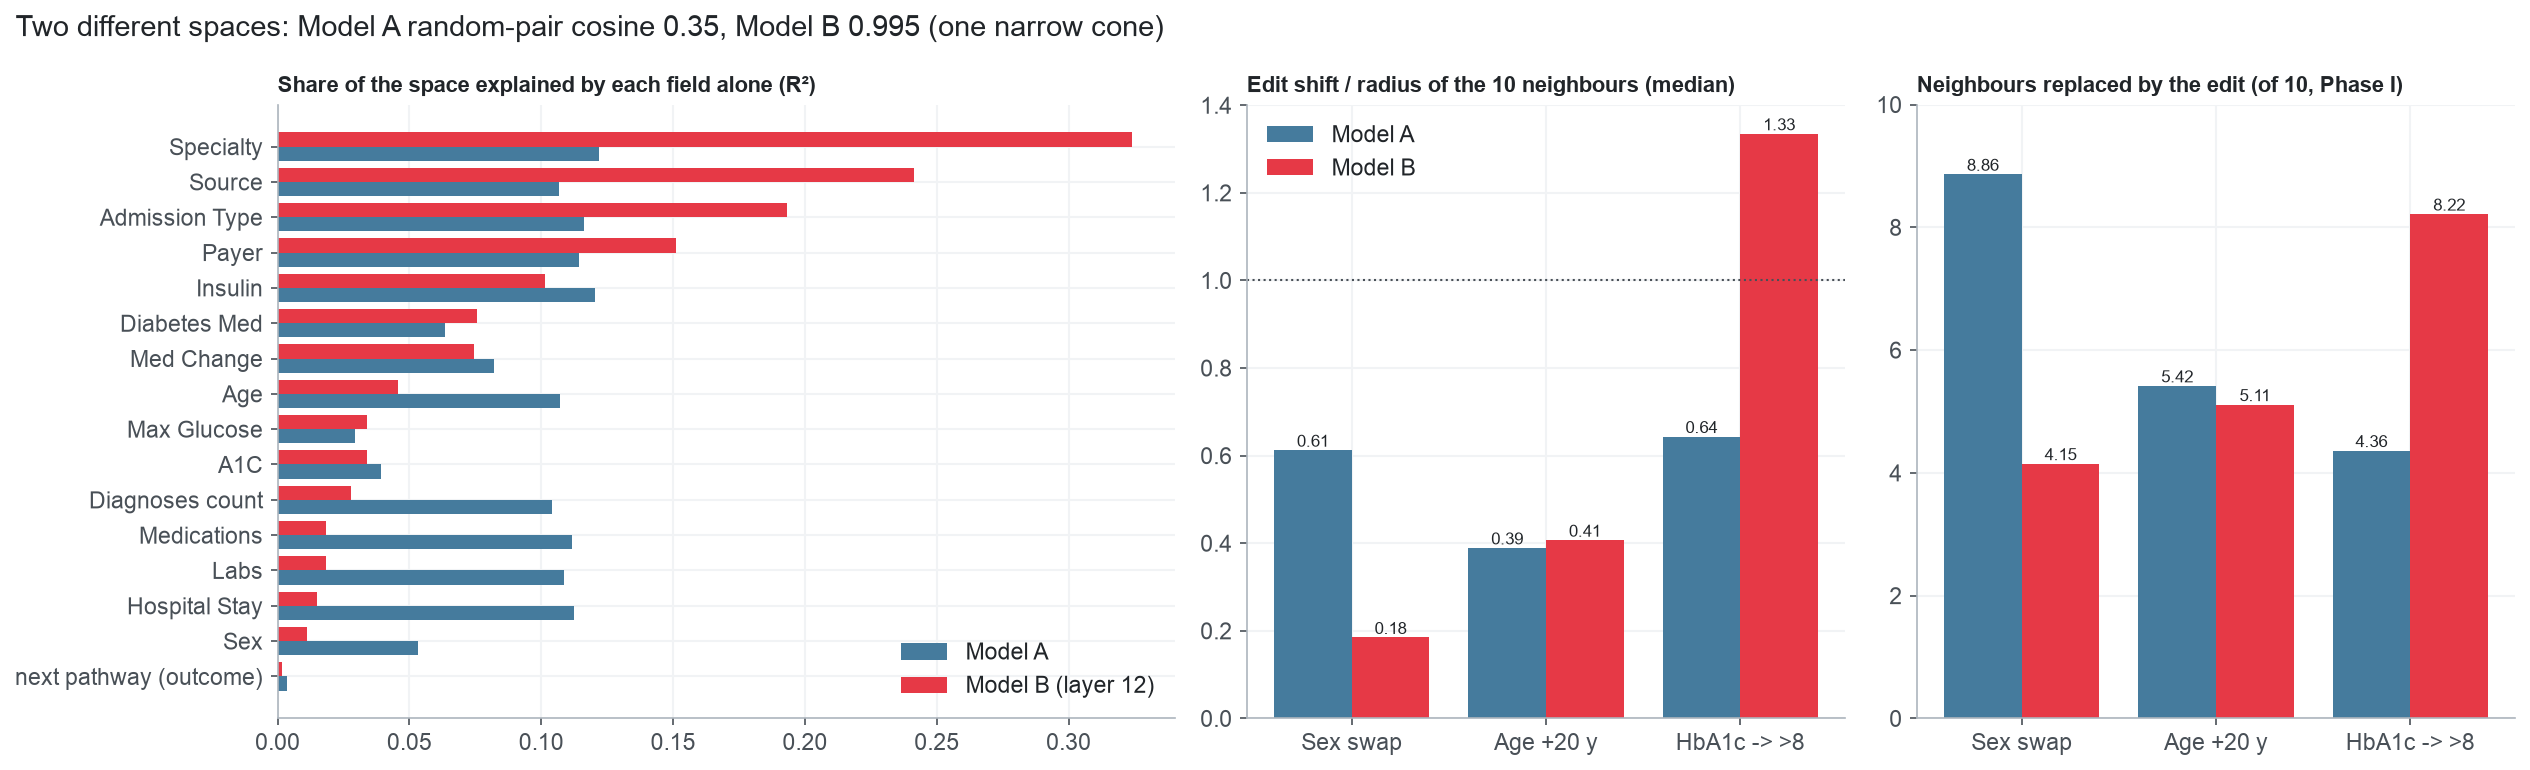

In [3]:
display(Image(FIG / "fig_compare_space_AB.png"))

**Fig. 1.** *Left:* share of the space explained by one field alone (R²). In Model A the fields are close to even (Specialty 0.12 … Max Glucose 0.03). In Model B the administrative fields dominate (Specialty 0.32, Source 0.24, Admission Type 0.19, Payer 0.15), and numbers such as age, labs and hospital stay explain almost nothing (≤ 0.05). The outcome explains 0.4 % of Model A's space and 0.15 % of Model B's: **neither space is organised by the next pathway**. Two random stays have cosine 0.35 in Model A and 0.995 in Model B, so only Model B is a narrow cone.

*Middle and right:* the same three edits as Phase I. They hit the models in **opposite** places:

| Edit | Model A shift / radius | Model A flips | Model B shift / radius | Model B flips |
|---|---|---|---|---|
| Sex swap | 0.61 | **8.86** | 0.18 | 4.15 |
| Age +20 y | 0.39 | 5.42 | 0.41 | 5.11 |
| HbA1c → >8 | 0.64 | 4.36 | 1.33 | **8.22** |

For Model A a sex swap changes one full one-hot unit. Every neighbour of the same sex loses ~0.07 similarity, and stays of the other sex gain as much, so 8.9 of 10 neighbours change although the shift is smaller than the radius. Model B hardly reads "Sex: Male" vs "Female" (0.18) but reacts to the HbA1c token change (Model B notebook, Section 3). The shift / radius ratio predicts the flips in both models (Spearman A 0.58 / 0.50 / 0.23, B 0.73 / 0.73 / 0.66). It is a weaker predictor for Model A, where ties between identical records are common.

## 3. What each model weighs, and what the outcome depends on

`15_model_a_shapley.py` plays the **same Shapley game** as for Model B (step 3) on the **same 300 stay pairs**: the fields of stay r are switched one by one to stay q's values, and each field gets its average change in similarity (200 permutations per pair for Model A, 20 for Model B; efficiency error < 3·10⁻⁷).

`17_supervised_reference.py` asks the data instead of the models: classifiers trained on the next pathway (patients split 80 / 20), and **permutation importance per field** (all of a field's columns shuffled together) for the gradient-boosting model.

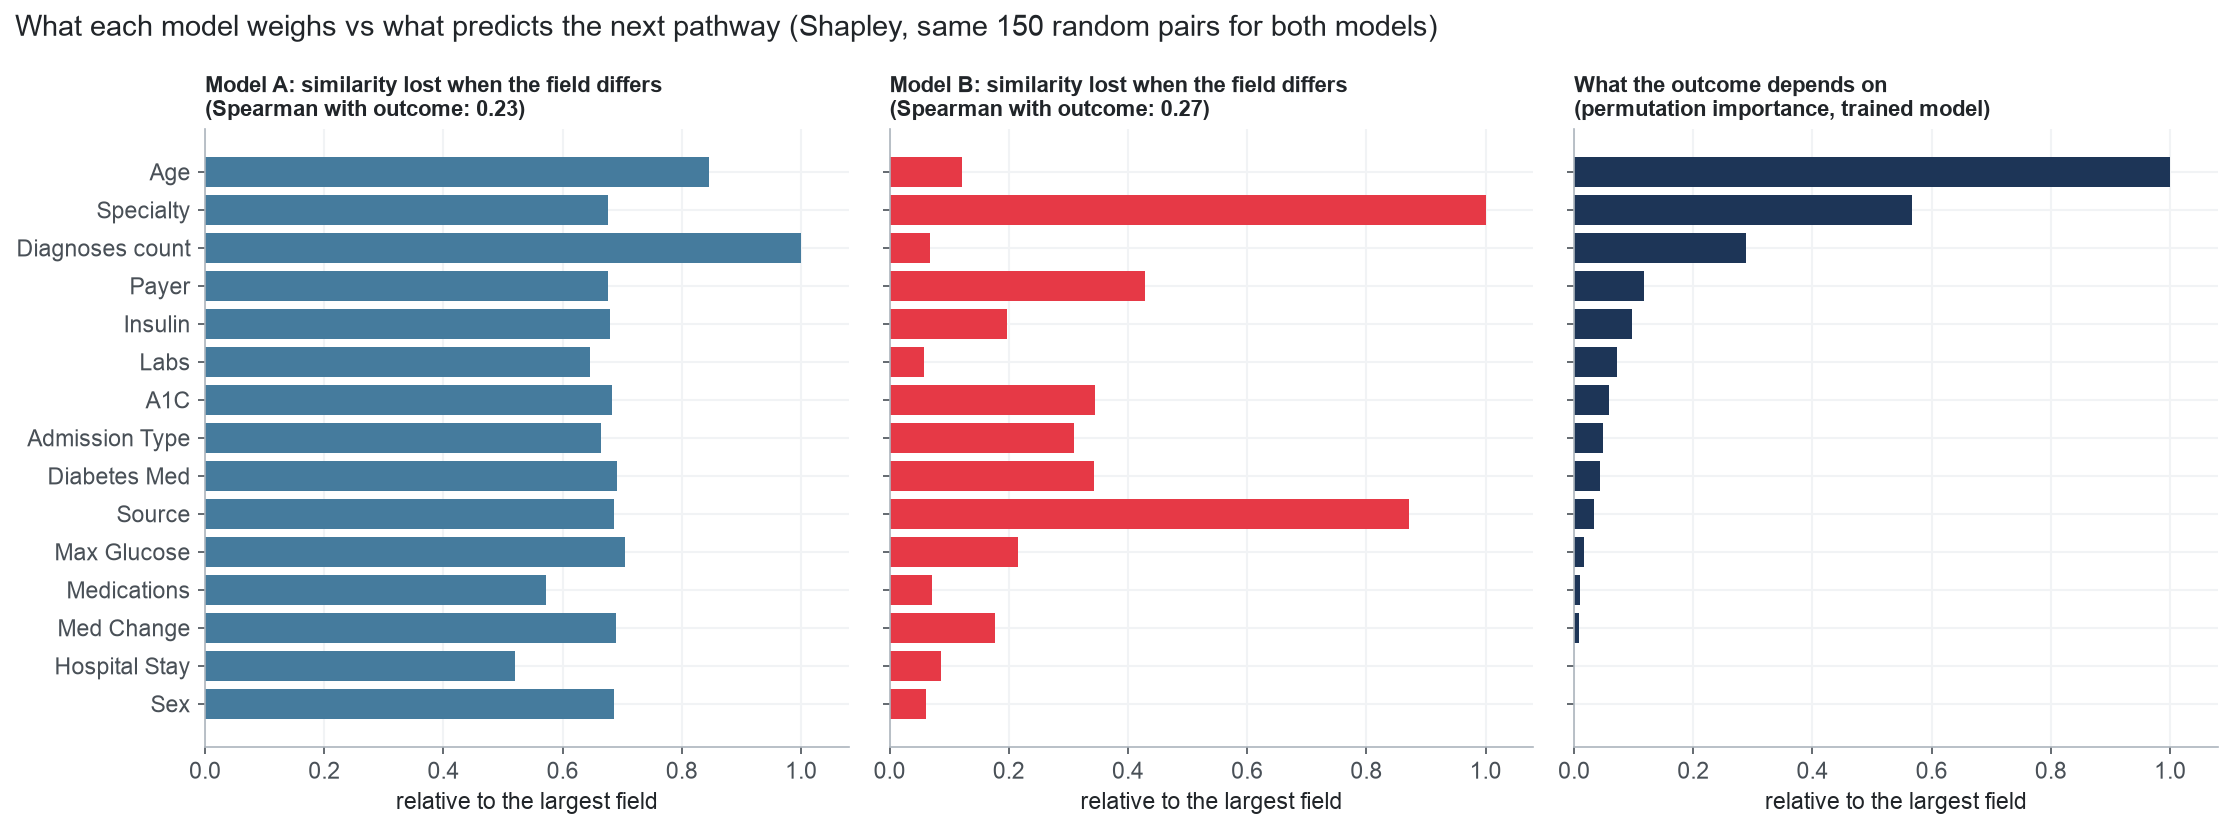

In [4]:
display(Image(FIG / "fig_compare_weights_AB.png"))

**Fig. 2.** *Model A* charges about the same for every differing field. The largest cost (diagnoses count) is 1.9× the smallest (hospital stay). *Model B* is very selective: specialty costs **17×** as much as a differing sex or lab count, and source and payer come next. The *outcome* depends mainly on **age**, then specialty, then the number of diagnoses. The other fields add little.

Neither model weighs the fields the way the outcome does (Spearman over the 15 fields: A 0.23, B 0.27). Their mistakes differ:
* **Model A** gives the outcome-relevant fields (age, specialty, diagnoses) the same weight as the irrelevant ones, so their signal is diluted by sex, payer, glucose …
* **Model B** gives specialty a strong weight, which helps, but also source and payer, which barely matter for the outcome. It nearly ignores age, the strongest predictor (0.12 of the largest cost).

In [5]:
sup = pd.read_csv(OUT / "supervised_reference.csv")
sup.round(3)

,model,trained_on_outcome,accuracy,macro_recall,Uncomplicated / Other,Cardiovascular,Kidney / Renal,Eye / Neurological
0,LogReg on Model A vector,True,0.292,0.372,0.212,0.460,0.373,0.442
1,Gradient boosting on Model A vector,True,0.358,0.385,0.284,0.526,0.340,0.390
2,LogReg on Model B embedding,True,0.318,0.370,0.249,0.463,0.353,0.416
3,Model A (KNN vote),False,0.627,0.262,0.859,0.188,0.000,0.000
4,Model B (KNN vote),False,0.628,0.264,0.854,0.200,0.000,0.000


**Table 2.** How much outcome signal is in the 15 fields at all? Classifiers **trained on the next pathway** reach a macro recall of **0.37–0.39** (chance 0.25), and they reach it on Model A's vector (0.37 logistic regression, 0.39 gradient boosting) as well as on Model B's frozen embedding (0.37). On the same test stays both models as used (10 neighbours, vote) reach 0.26: they never predict Kidney or Eye / Neuro. Their accuracy (63 %) is higher only because they mostly predict the majority class. The class-weighted classifiers trade accuracy for finding the rare pathways (Kidney recall 0.34–0.37 instead of 0).

So the signal is **weak but present, and present in both representations**. What loses it is the **neighbour vote on an unweighted cosine distance**, which is dominated by fields that do not predict the outcome. This corrects our earlier reading in the Model B notebook (Section 9: "the 15 fields carry very little information"). There, the head fine-tuned for one epoch stayed at chance because it was undertrained, not because the signal was missing.

### What "the same weak outcome signal" means

**Signal** = can the next pathway (Uncomplicated, Cardiovascular, Kidney, Eye/Neuro) be guessed from the 15 fields better than by chance? To find out, we trained classifiers whose only job is to predict the next pathway from those fields.

| | Macro recall |
|---|---|
| Random guessing (4 pathways) | 0.25 |
| Classifier trained on **Model A's** vector | 0.37–0.39 |
| Classifier trained on **Model B's** vector | 0.37 |
| Model A / Model B as used (10 neighbours, vote) | 0.26 |
| A perfect predictor | 1.00 |

* **Weak:** 0.37 is clearly better than guessing, but far from good: about 1 in 3 stays per pathway is right. Mainly age, specialty and the number of diagnoses help (Fig. 2, right). The other fields add almost nothing.
* **The same:** a classifier gets about the same score from Model A's numbers as from Model B's sentence vector. Both vectors hold this small piece of information, about equally.
* **Lost by the vote:** Model A and Model B do not use a trained classifier. They take the 10 most similar stays and vote, and the similarity is built on the wrong fields. Model A counts all 15 fields equally, so the 3 useful ones are drowned out. Model B matches mainly department, admission source and payer, and ignores age. So the vote scores 0.26, close to chance, and never predicts Kidney or Eye/Neuro.

**In one line:** the data predicts the next pathway weakly; both models carry that information but lose it, because they choose neighbours by the wrong fields.

## 4. ICE / PDP: does the vote follow the data?

`16_model_a_ice.py` repeats step 10 with Model A on the **same 300 stays**: each stay's age is set to every bracket (and A1C to every value), the 10 nearest other-patient stays are retrieved, and the Cardiovascular vote share is recorded.

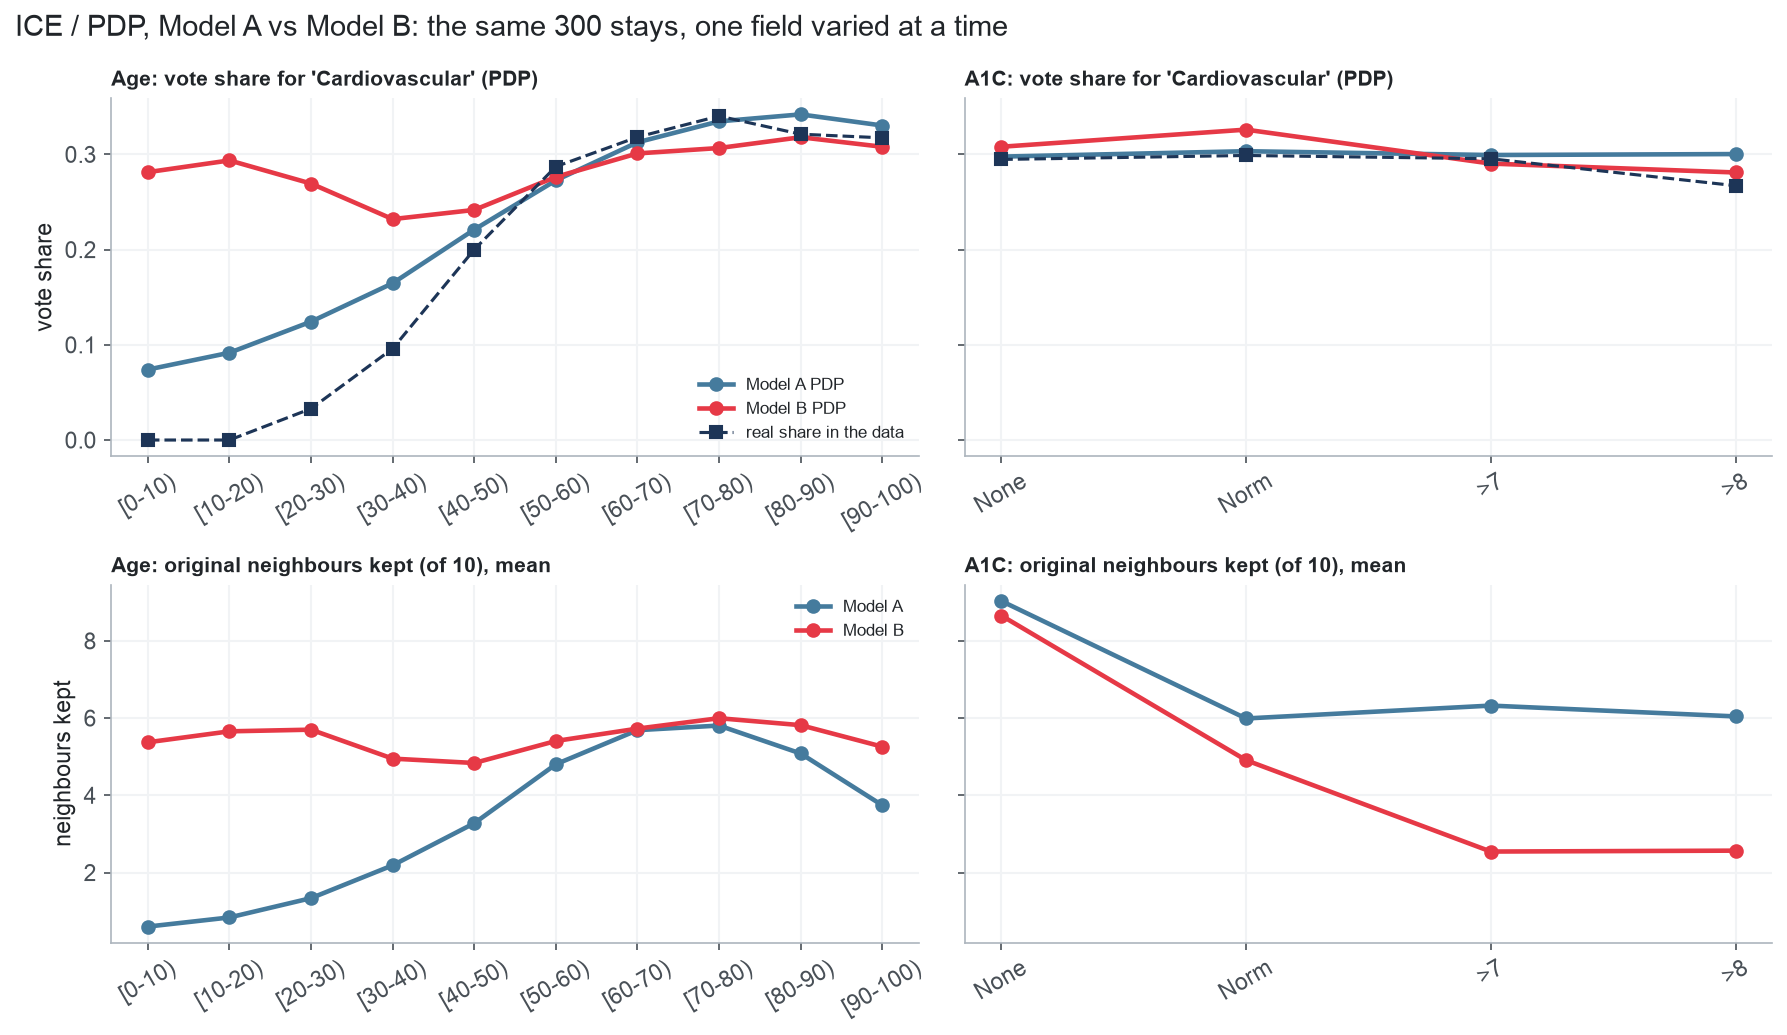

,Model A,Model B
value,,
[0-10),0.074,0.281
[10-20),0.092,0.294
[20-30),0.124,0.269
[30-40),0.165,0.232
[40-50),0.221,0.242
[50-60),0.273,0.276
[60-70),0.313,0.301
[70-80),0.335,0.307
[80-90),0.342,0.318


In [6]:
display(Image(FIG / "fig_ice_pdp_AB.png"))
ia, ib = pd.read_parquet(OUT / "ice_A.parquet"), pd.read_parquet(OUT / "ice_B.parquet")
pd.DataFrame({m: r[r.field == "Age"].groupby("value").vote_share_cardio.mean() for m, r in [("Model A", ia), ("Model B", ib)]}).round(3)

**Fig. 3.** **Age:** in the data the Cardiovascular share rises from 0 (under 20) to 0.34 (70–80). Model A's PDP follows that curve (0.07 → 0.34), because age is a number and older stays are closer. Model B's PDP is **flat** (0.23–0.32): to Bio_ClinicalBERT "[30-40)" and "[70-80)" are nearly the same tokens, so it keeps about 5 of 10 neighbours whatever the age. Model A keeps fewer when the age moves far from the stay's real one. **HbA1c:** neither the data (0.30 → 0.27) nor either model reacts much in the vote. But Model B swaps out 7.4 of its 10 neighbours for ">7" and ">8", against about 4 for Model A. It **changes neighbours without changing the decision**: fragility that carries no meaning.

## 5. The same stays in both spaces

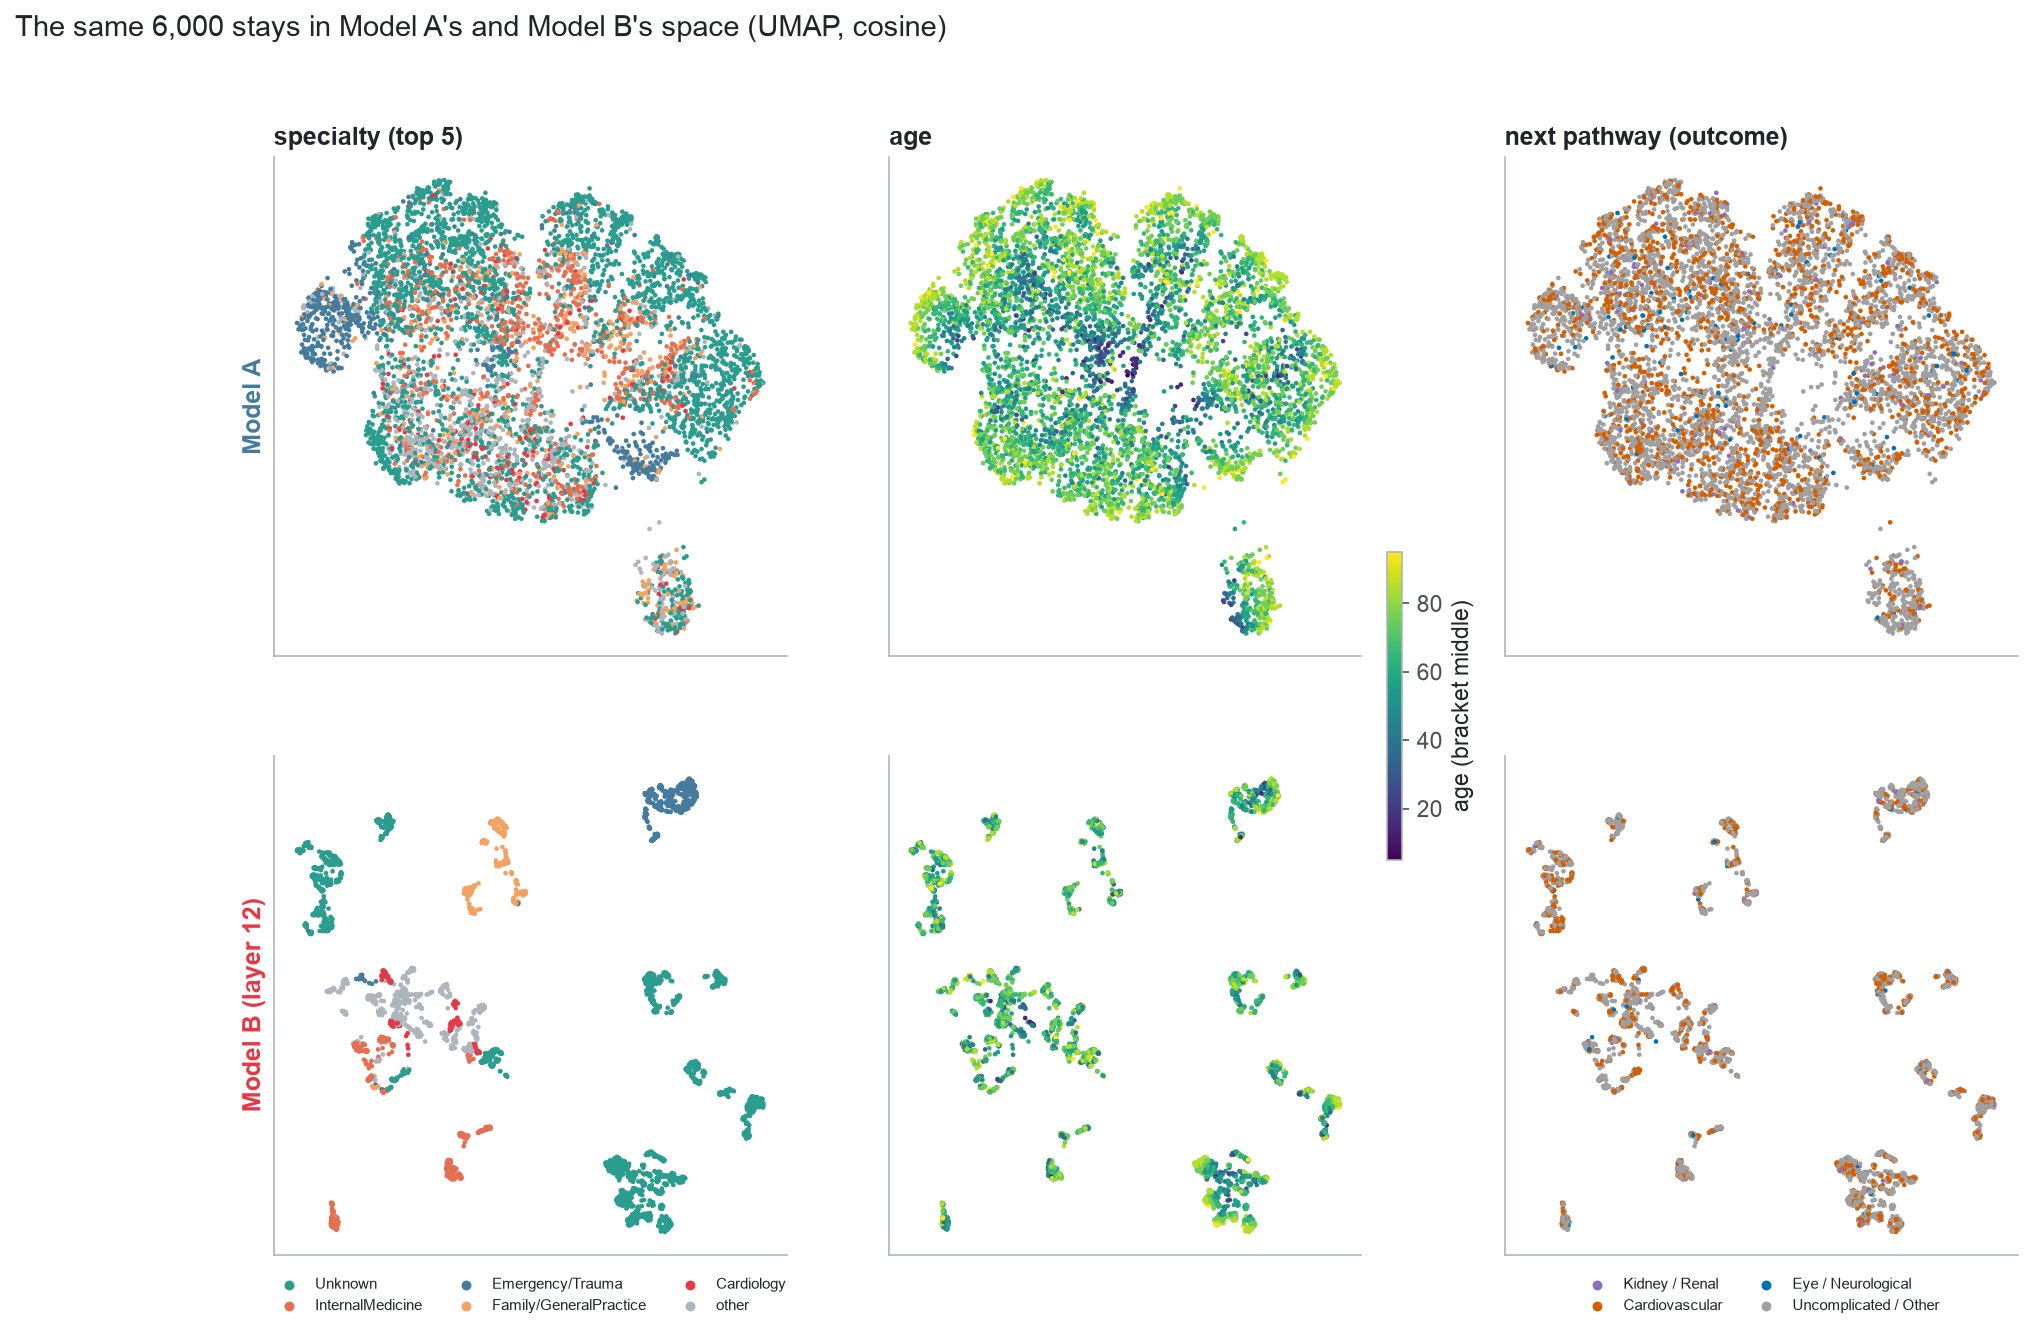

In [7]:
display(Image(FIG / "fig_compare_umap_AB.png"))

**Fig. 4.** The same 6,000 stays (UMAP, cosine). **Model A** forms one connected cloud with smooth age gradients and specialties mixed together. A few small separate groups are stays that share several categorical values (e.g. the Emergency/Trauma group at the left). **Model B** breaks into separate islands, one per specialty, with age scattered inside each island. In neither map does the next pathway form a region: the Cardiovascular stays (orange) are spread over the whole map. This is the visual version of Fig. 1: the variance share of the outcome is < 0.5 % in both models. UMAP keeps local structure only, so distances between islands are not meaningful.

## 6. Groups: who is right, and who is fragile?

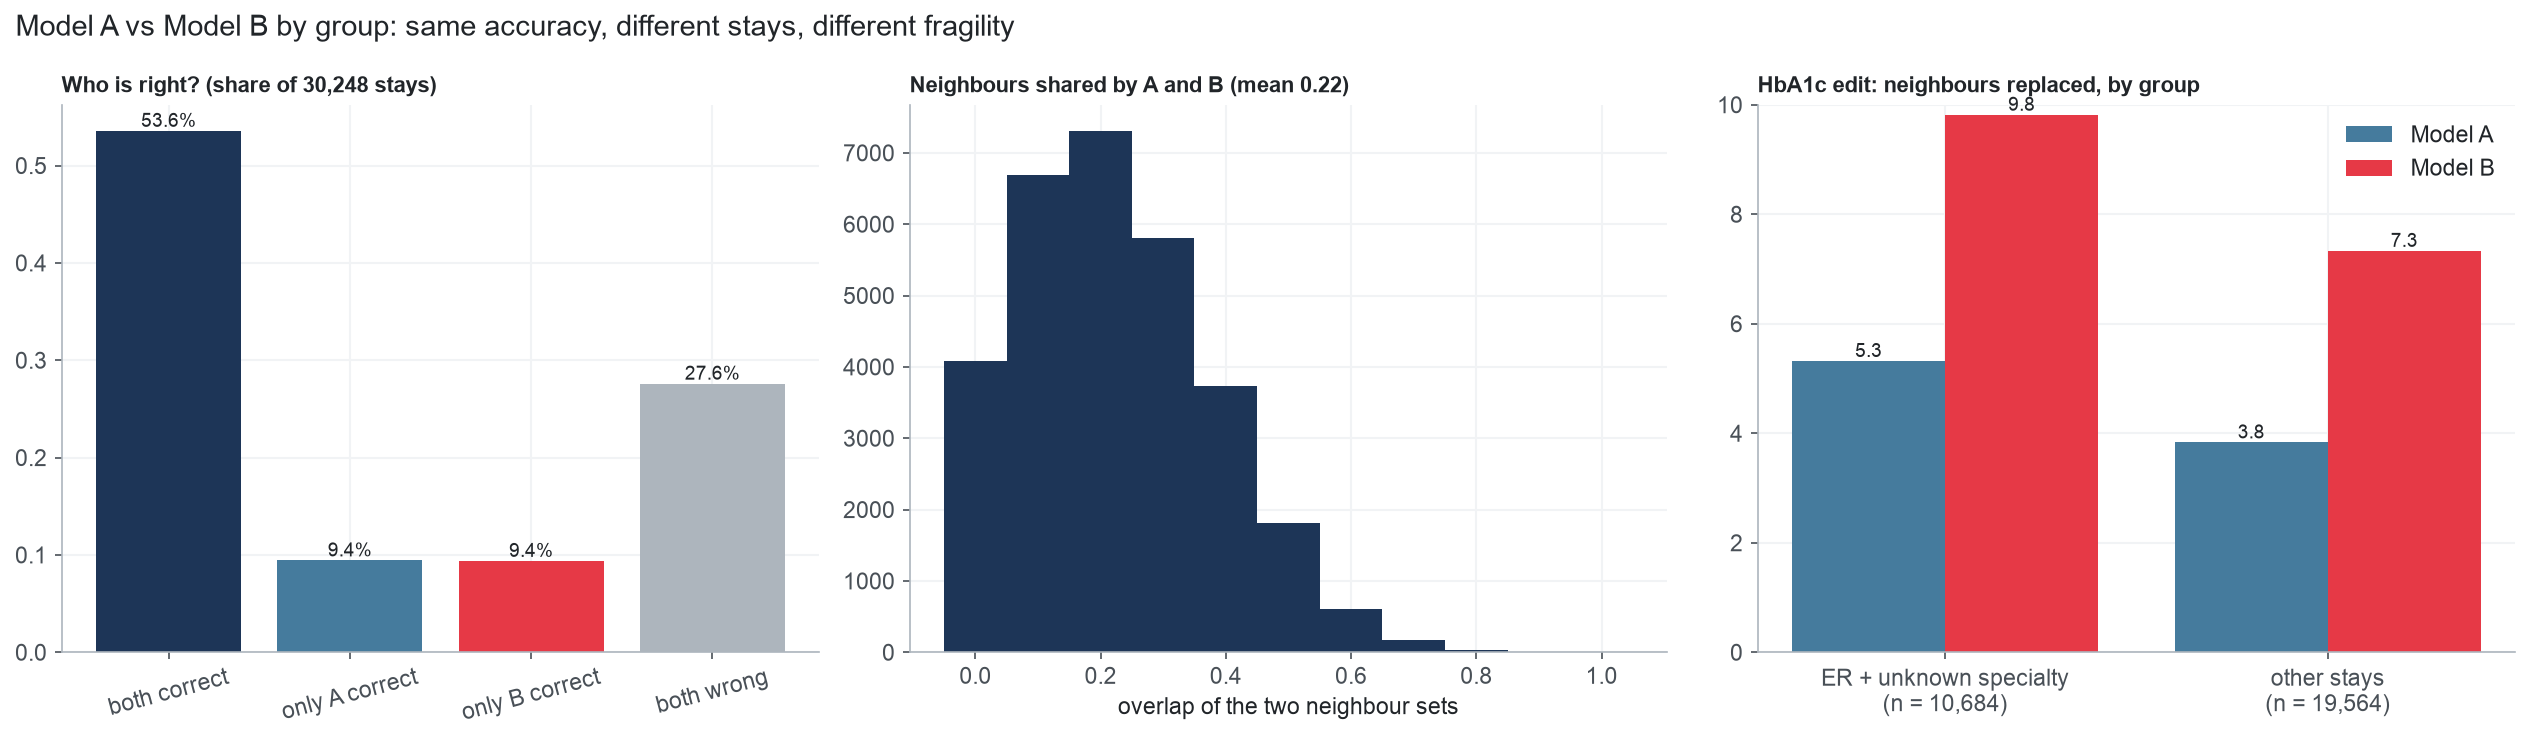

,group,n,share,A accuracy,B accuracy,A-B neighbour overlap,A HbA1c flips,B HbA1c flips,A median d10,B median d10,"same prediction A,B"
0,all stays,30248,1.000,0.630,0.630,0.224,4.363,8.216,0.113,0.001,0.804
1,ER + unknown specialty,10684,0.353,0.620,0.614,0.224,5.320,9.818,0.077,0.000,0.805
2,other stays,19564,0.647,0.636,0.638,0.224,3.834,7.332,0.134,0.001,0.804
3,both correct,16204,0.536,1.000,1.000,0.223,4.333,8.134,0.117,0.001,1.000
4,only A correct,2856,0.094,1.000,0.000,0.209,4.358,8.225,0.109,0.001,0.000
5,only B correct,2840,0.094,0.000,1.000,0.208,4.386,8.242,0.113,0.001,0.000
6,both wrong,8348,0.276,0.000,0.000,0.237,4.413,8.361,0.108,0.001,0.973


In [8]:
display(Image(FIG / "fig_compare_groups_AB.png"))
pd.read_csv(OUT / "compare_groups_AB.csv").round(3)

**Fig. 5 / Table 3.**
* **Same accuracy, different stays.** Both models are right on 53.6 % of stays and both wrong on 27.6 %. On the remaining **18.8 %** exactly one of them is right, split evenly: 9.4 % only A, 9.4 % only B. They make the same prediction on 80.4 % of stays, but the neighbour sets overlap by only 22 % (2.2 of 10). Mostly they vote "Uncomplicated" from different neighbours.
* **Crowded group.** Stays admitted through the Emergency Room with unknown specialty (10,684, 35 %) sit in the densest part of both spaces: the radius of the 10 neighbours is 0.077 vs. 0.134 for other stays in Model A, and 0.0004 vs. 0.0007 in Model B. They are a little less accurate in both models (62 % vs. 64 %) and more fragile: the HbA1c edit replaces 9.8 of 10 neighbours in Model B and 5.3 in Model A, against 7.3 and 3.8 for the other stays.
* **Fragile in one ≠ fragile in the other.** 70.6 % of stays lose ≥ 8 neighbours to the HbA1c edit in Model B, only 14.0 % in Model A, and 12.4 % in both. The per-stay flip counts correlate only moderately (Spearman 0.41). Fragility is a property of **the model and the edit**, not of the patient.

## 7. Answers: Model A vs Model B

| | Model A (feature vector) | Model B (Bio_ClinicalBERT) |
|---|---|---|
| Space | open (random cosine 0.35), fields about equal | narrow cone (0.995), ordered by specialty / source / payer |
| What makes stays similar | every field about equally (max/min Shapley cost 1.9×) | specialty, source, payer (17×); sex, labs, age barely |
| Age (strongest outcome predictor) | used: PDP follows the data | ignored: flat PDP |
| Fragile to | sex swap (8.9 flips), via one-hot design | HbA1c (8.2 flips), via the tokens |
| Outcome signal in the representation | present (trained classifier 0.37–0.39 macro recall) | present (0.37) |
| KNN vote | 0.26 macro recall, 63.0 % accuracy | 0.26 macro recall, 63.0 % accuracy |

**In one sentence:** both models hold the same weak outcome signal, and both lose it in an unweighted cosine neighbour vote, for opposite reasons. Model A weighs all 15 fields equally, so age, specialty and diagnoses are drowned out. Model B weighs the department words most, so it ignores age. Their equal accuracy comes from two different mistakes, which is why they agree on the prediction but rarely on the neighbours.

**What this suggests (not tested here):** a neighbour model that weighs fields by their outcome importance (e.g. scaling Model A's columns by Fig. 2 *right*) should keep Model A's transparency and use the signal both models currently waste.

**Limitations.** Shapley on 300 pairs (Model B 20 permutations, Model A 200); permutation importance comes from one gradient-boosting model and one split; the supervised classifiers are not tuned; ICE on 300 stays; UMAP shows local structure only; "fragile" uses the Phase I flip counts of the HbA1c edit only.